# 09 — Counterfactual sensitivity: what do our models respond to?

## Purpose

We already measured **conflict reliance**, which asks *which rule does the model follow when the rules disagree?* This notebook adds two **paired intervention metrics**, applied consistently to every training condition:

1. **Hard prediction flip rate:** fraction of normal samples whose predicted class changes after intervening on one feature group.
2. **Mean absolute probability change:** average `|sigmoid(logit_before) - sigmoid(logit_after)|`.

Start from a valid normal input `X = [T, αU, αUT]` where both features agree. A **simple flip** makes `[-T, αU, αUT]`. A **complex flip** makes `[T, αU, -αUT]`, reversing the complex rule. Both counterfactuals are outside the training distribution; neither receives a ground-truth label.

**Research design:** These are additional *measurements*, not additional *controls*. Run them on ordinary scaling, inverse initialization, and compensated SGD. The main runner now records them during training, so this notebook reads its CSVs without retraining.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

results = Path('results')
if not (results / 'final_summary.csv').exists() and (Path('..') / 'results/final_summary.csv').exists():
    results = Path('..') / 'results'
final = pd.read_csv(results / 'final_summary.csv')
metrics = ['simple_flip_rate', 'complex_flip_rate', 'simple_probability_change', 'complex_probability_change']
missing = [m for m in metrics if m not in final.columns]
if missing:
    raise RuntimeError(f'Missing columns {missing}. Re-run python run_all_experiments.py with the updated project.')
print(final[['experiment', 'seed', 'alpha', *metrics]].head())

        experiment  seed  alpha  simple_flip_rate  complex_flip_rate  \
0         ordinary    42    0.1               1.0                0.0   
1     inverse_init    42    0.1               1.0                0.0   
2  compensated_sgd    42    0.1               1.0                0.0   
3         ordinary    42    0.5               1.0                0.0   
4     inverse_init    42    0.5               1.0                0.0   

   simple_probability_change  complex_probability_change  
0                   0.961962                    0.001538  
1                   0.930925                    0.030128  
2                   0.891750                    0.070357  
3                   0.957704                    0.008678  
4                   0.925064                    0.035486  


## Comparison 1 — Final sensitivity versus α

Each line is the **mean across seeds**. Shading shows ±1 sample standard deviation, not a confidence interval. Compare the two feature groups *within* each training condition. Large hard-flip rates mean the model frequently changes its predicted class; probability-change metrics measure softer responses too.

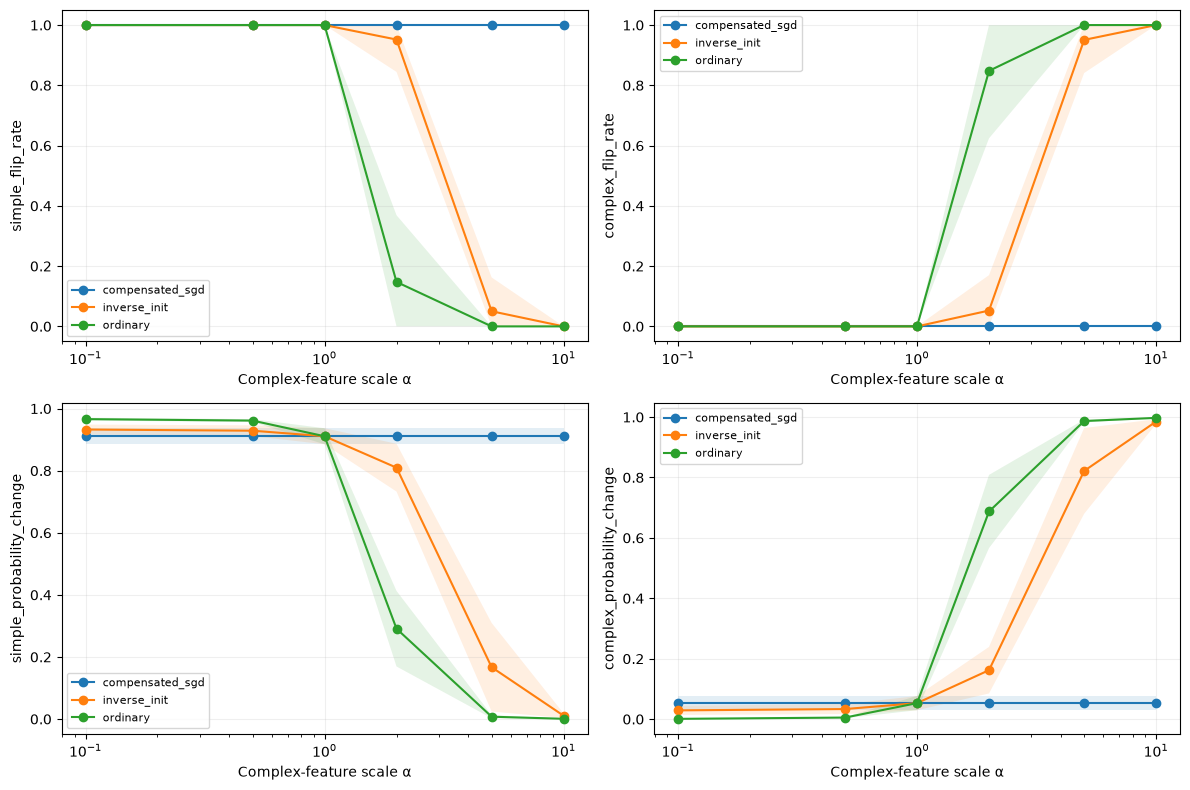

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metrics):
    for experiment, group in final.groupby('experiment'):
        agg = group.groupby('alpha')[metric].agg(['mean', 'std']).sort_index()
        ax.plot(agg.index, agg['mean'], marker='o', label=experiment)
        ax.fill_between(agg.index, (agg['mean']-agg['std'].fillna(0)).clip(lower=0),
                        (agg['mean']+agg['std'].fillna(0)).clip(upper=1), alpha=0.12)
    ax.set_xscale('log')
    ax.set_xlabel('Complex-feature scale α')
    ax.set_ylabel(metric)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
figures = results / 'figures'
figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / 'combined_counterfactual_sensitivity.png', dpi=170, bbox_inches='tight')
plt.show()

## Comparison 2 — Per-seed values at α = 5

Averages can hide disagreement between seeds. Inspect individual runs before interpreting the result as robust.

In [3]:
display(final.loc[final.alpha == 5, ['experiment', 'seed', 'alpha', 'complex_reliance', *metrics]].sort_values(['experiment','seed']))

,experiment,seed,alpha,complex_reliance,simple_flip_rate,complex_flip_rate,simple_probability_change,complex_probability_change
14,compensated_sgd,42,5.0,0.00,1.000000,0.000000,0.891750,0.070357
32,compensated_sgd,43,5.0,0.00,1.000000,0.000000,0.878146,0.085025
50,compensated_sgd,44,5.0,0.00,1.000000,0.000000,0.923299,0.042672
68,compensated_sgd,45,5.0,0.00,1.000000,0.000000,0.919201,0.038220
86,compensated_sgd,46,5.0,0.00,1.000000,0.000000,0.942642,0.029097
13,inverse_init,42,5.0,1.00,0.000000,1.000000,0.100014,0.891023
31,inverse_init,43,5.0,1.00,0.000000,1.000000,0.078973,0.907085
49,inverse_init,44,5.0,1.00,0.000000,1.000000,0.172670,0.814651
67,inverse_init,45,5.0,1.00,0.000000,1.000000,0.071463,0.917476
85,inverse_init,46,5.0,0.75,0.250977,0.753906,0.411940,0.578008


## Interpretation and caveats

- Does complex sensitivity increase with α under ordinary scaling and inverse initialization?
- Does compensated SGD reproduce the α=1 reference behavior?
- Are hard-flip rates and probability changes consistent? If not, the model may be changing confidence without changing class.
- A large flip rate is a **behavioral sensitivity measure**, not proof of an internal representation.
- Both interventions are **out of distribution**; do not report them as ordinary test accuracy.
- These tests operate on the same four underlying prototypes repeated across the dataset. Interpret uncertainty across **seeds**, not as independent evidence from 1,024 novel patterns.